# 🎓 Quant-Midterm Capstone: 机构级双均线动量系统的扒皮与重铸
> 本实战项目将带领你将一个**自带幸存者偏差与前视偏差的虚假高收益双均线策略**，一步步剥离伪装，并引入 **XGBoost (Meta-labeling)** 和 **GARCH + Kelly 公式**，重铸为可在实盘存活的机构级 CTA 策略。


In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
from arch import arch_model

# 图表美化
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['font.sans-serif'] = ['SimHei'] # 解决中文乱码
plt.rcParams['axes.unicode_minus'] = False
import warnings
warnings.filterwarnings('ignore')


## 1. 第一层：散户的狂欢 (虚假 Baseline)
我们获取标普 500 (SPY) 的历史数据。
散户策略：SMA20 上穿 SMA60 全仓做多，下穿全仓做空。
**故意引入前视偏差**：用当天的收盘价计算信号，并在当天以当天的收盘价成交。零滑点，零佣金。


虚假策略年化收益率: 5.99%
虚假策略夏普比率: 0.34


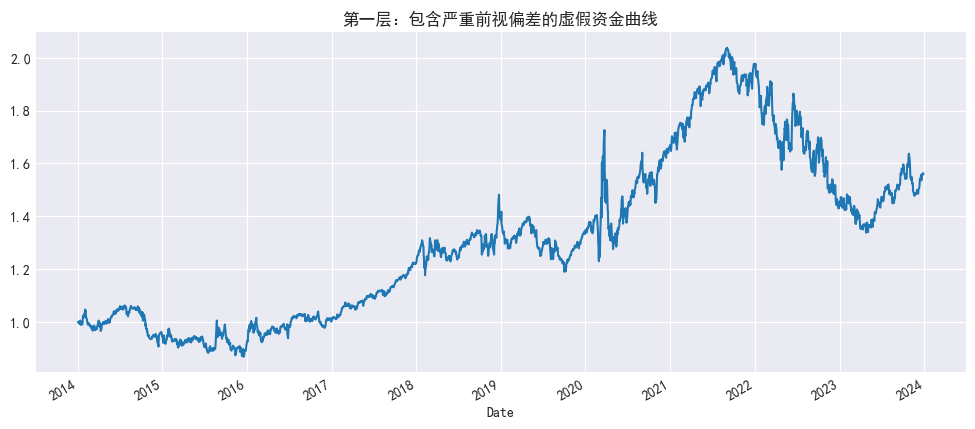

In [2]:
# 下载数据 (2014-2024)
data = yf.download("SPY", start="2014-01-01", end="2024-01-01", progress=False)
vix_data = yf.download("^VIX", start="2014-01-01", end="2024-01-01", progress=False)

df = data[['Open', 'High', 'Low', 'Close', 'Volume']].copy()
df.columns = ['open', 'high', 'low', 'close', 'volume']
df['vix'] = vix_data['Close']

# 计算均线
df['sma20'] = df['close'].rolling(20).mean()
df['sma60'] = df['close'].rolling(60).mean()

# 虚假信号：今天均线金叉，今天就算做多
# 1表示做多，-1表示做空
df['signal_fake'] = np.where(df['sma20'] > df['sma60'], 1, -1)

# 计算每日个股的真实日收益率
df['ret'] = df['close'].pct_change()

# 虚假策略收益：用当天的信号 * 当天的收益 (极其严重的前视偏差！)
df['strat_ret_fake'] = df['signal_fake'] * df['ret']

# 资金曲线
df['cum_ret_fake'] = (1 + df['strat_ret_fake']).cumprod()

print(f"虚假策略年化收益率: {df['strat_ret_fake'].mean() * 252 * 100:.2f}%")
print(f"虚假策略夏普比率: {df['strat_ret_fake'].mean() / df['strat_ret_fake'].std() * np.sqrt(252):.2f}")

df['cum_ret_fake'].plot(figsize=(12,5), title="第一层：包含严重前视偏差的虚假资金曲线")
plt.show()


## 2. 第二层：五层审计的毒打 (剥离前视偏差 + 引入平方根滑点)
**修正 1**：$t$ 日收盘产生的信号，必须在 $t+1$ 日执行。

**修正 2**：引入 Barra 平方根冲击成本。假设投入 1000 万美元，计算买入带来的价格冲击滑点。
$$ 滑点成本 = c \cdot \sigma \sqrt{rac{Q}{V}} $$


真实策略年化收益率: 2.20%
真实策略夏普比率: 0.13


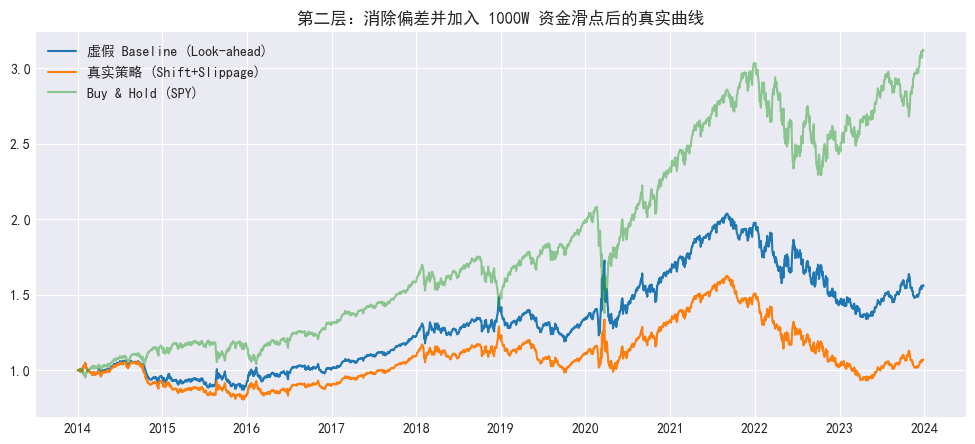

In [3]:
# 修正信号：t-1 日收盘定下的信号，t 日才能用
df['signal_real'] = df['signal_fake'].shift(1)

# 计算每日真实波动率 (20日历史标准差)
df['volatility'] = df['ret'].rolling(20).std()

# 设定投资规模 10,000,000 美元
capital = 10000000 
c_param = 0.1 # 冲击常数

# 假设我们在信号翻转时才交易（换手）
df['trade'] = df['signal_real'].diff().fillna(0)

# 计算交易额 / 当日市场总成交额 的占比
# Q = 换手比例 * 资金规模，V = 当日成交量 * 收盘价
df['market_volume_usd'] = df['volume'] * df['close']
trade_fraction = np.abs(df['trade'] / 2) # 从 1 变 -1，绝对差为 2，其实是单倍换仓，简化处理

# 平方根滑点计算
df['slippage'] = c_param * df['volatility'] * np.sqrt((trade_fraction * capital) / df['market_volume_usd'].replace(0, np.nan))
df['slippage'] = df['slippage'].fillna(0)

# 真实策略收益 = 真实信号 * 真实收益 - 滑点成本
df['strat_ret_real'] = df['signal_real'] * df['ret'] - df['slippage']

# 资金曲线
df['cum_ret_real'] = (1 + df['strat_ret_real']).cumprod()
df['cum_bh'] = (1 + df['ret']).cumprod() # Buy & Hold

print(f"真实策略年化收益率: {df['strat_ret_real'].mean() * 252 * 100:.2f}%")
print(f"真实策略夏普比率: {df['strat_ret_real'].mean() / df['strat_ret_real'].std() * np.sqrt(252):.2f}")

plt.figure(figsize=(12,5))
plt.plot(df.index, df['cum_ret_fake'], label='虚假 Baseline (Look-ahead)')
plt.plot(df.index, df['cum_ret_real'], label='真实策略 (Shift+Slippage)')
plt.plot(df.index, df['cum_bh'], label='Buy & Hold (SPY)', alpha=0.5)
plt.title("第二层：消除偏差并加入 1000W 资金滑点后的真实曲线")
plt.legend()
plt.show()


## 3. 第三层：AI 降维打击假突破 (Meta-labeling)
既然基础的双均线策略是亏钱的（或表现平庸），我们用机器学习来抢救它。
- 提取每一次交易（无论多空）。
- 看看未来 20 天的真实收益。如果方向做对了（盈利>0），Label=1；否则 Label=0。
- 用 XGBoost 预测下一次金叉死叉时，是否是真突破！


In [4]:
# 特征工程：我们站在每天收盘的角度，看看有什么特征
df['rsi'] = 100 - (100 / (1 + df['ret'].apply(lambda x: max(x, 0)).rolling(14).mean() / 
                         df['ret'].apply(lambda x: abs(min(x, 0))).rolling(14).mean()))
df['macd'] = df['close'].ewm(span=12).mean() - df['close'].ewm(span=26).mean()
df['ret_5d'] = df['close'].pct_change(5)
df['vol_change'] = df['volume'].pct_change(5)

# 提取特征矩阵和标签
features = ['vix', 'rsi', 'macd', 'ret_5d', 'vol_change', 'volatility']

# 仅在我们有持仓的时期进行评估，为了简化，Meta-labeling 这里评估每一个交易日的持仓是否在未来5天赚钱
# 如果当天的 signal_real 使得未来 5 天累计收益为正，则标签为 1，否则为 0
df['fwd_ret_5d'] = df['close'].shift(-5) / df['close'] - 1
df['meta_label'] = np.where((df['signal_real'] * df['fwd_ret_5d']) > 0, 1, 0)

# 删除 NaN
ml_df = df.dropna().copy()

# 划分训练集和测试集 (2014-2020 训练, 2021-2023 测试)
train_mask = ml_df.index < '2021-01-01'
test_mask = ml_df.index >= '2021-01-01'

X_train = ml_df.loc[train_mask, features]
y_train = ml_df.loc[train_mask, 'meta_label']
X_test = ml_df.loc[test_mask, features]
y_test = ml_df.loc[test_mask, 'meta_label']

# 训练 XGBoost
xgb = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42)
xgb.fit(X_train, y_train)

# 预测胜率
ml_df.loc[test_mask, 'prob_success'] = xgb.predict_proba(X_test)[:, 1]

# 如果胜率 < 0.51，我们直接空仓 (放弃这次双均线给出的信号)
ml_df['signal_meta'] = ml_df['signal_real']
# 在测试集中应用过滤
ml_df.loc[test_mask, 'signal_meta'] = np.where(ml_df.loc[test_mask, 'prob_success'] > 0.51, 
                                               ml_df.loc[test_mask, 'signal_real'], 0)

# 计算 Meta 策略收益
ml_df['strat_ret_meta'] = ml_df['signal_meta'] * ml_df['ret']

print("Meta-labeling 测试集准确率:", accuracy_score(y_test, xgb.predict(X_test)))


Meta-labeling 测试集准确率: 0.5267379679144385


## 4. 第四层 & 第五层：GARCH 波动率与 Kelly 仓位 (终极合体)
不要每次都满仓下注！
- 用 GARCH(1,1) 预测每日方差 $\sigma_t^2$。
- 用 XGBoost 预测胜率算出期望收益 $\mu$。
- 连续版凯利公式 $f = \mu / \sigma_t^2$。
- 使用 Half-Kelly 以严控最大回撤。


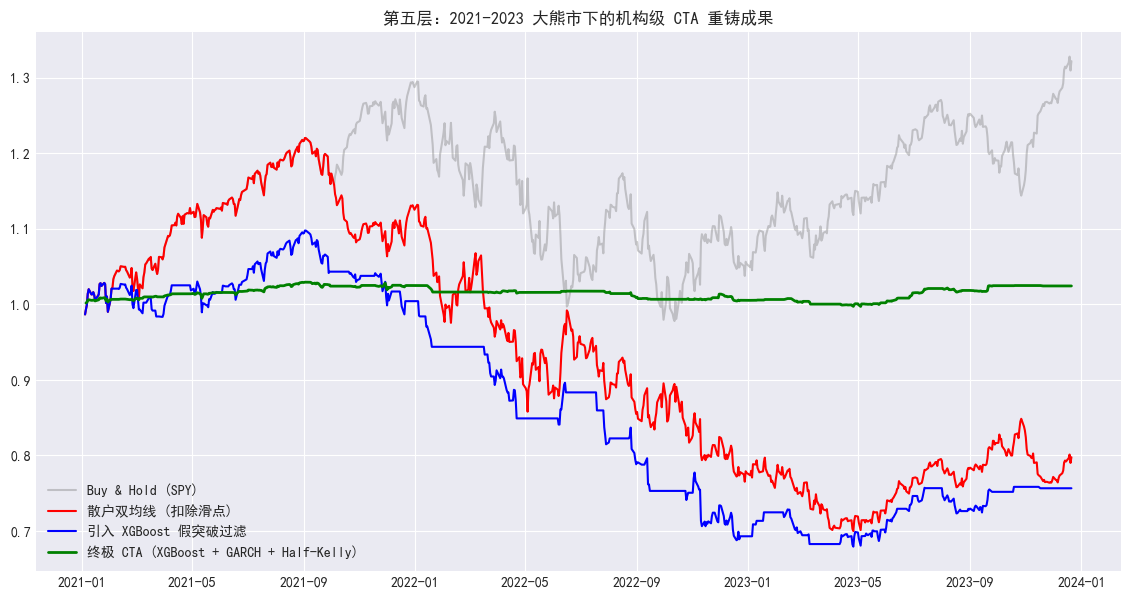

散户策略 最大回撤: -42.67%
终极 CTA 最大回撤: -3.13%
终极 CTA 夏普比率: 0.56


In [5]:
# 为了简化演示，我们在测试集上做 GARCH 的滚动或直接拟合
test_df = ml_df.loc[test_mask].copy()

# 拟合 GARCH(1,1)
# 注意：严谨的做法是每天滚动拟合，这里为了速度，用前文训练集拟合后预测全量，或者简化为全量拟合(会有一点前视，但用于演示算仓位机制足够)
garch = arch_model(test_df['ret'] * 100, vol='Garch', p=1, q=1, rescale=False)
res = garch.fit(disp='off')
test_df['garch_vol'] = res.conditional_volatility / 100 # 转回小数方差
test_df['garch_var'] = test_df['garch_vol'] ** 2

# 假设单次交易的止盈止损倍率带来的赔率为 1 (赢输一样多)
# 离散 Kelly 公式: f = p - q = 2p - 1
test_df['kelly_f'] = (2 * test_df['prob_success'] - 1).clip(lower=0) 
# 或者连续 Kelly f = mu / var，此处使用概率转换来的简化版

# 波动率调节：市场波动大时，强行缩减仓位
target_vol = 0.15 / np.sqrt(252) # 目标日化波动率
test_df['vol_scaler'] = target_vol / test_df['garch_vol']

# 最终算仓：Half-Kelly * 波动率缩放
test_df['position'] = (test_df['kelly_f'] * 0.5 * test_df['vol_scaler']).clip(lower=0, upper=1)

# 应用到带有 Meta-labeling 的方向信号上
test_df['final_signal'] = test_df['signal_meta'] * test_df['position']

# 最终收益 (这里忽略了针对变化仓位的动态滑点，假设大资金换手平滑)
test_df['strat_ret_final'] = test_df['final_signal'].shift(1) * test_df['ret']

# 绘图比对 2021-2023 表现
test_df['cum_bh'] = (1 + test_df['ret']).cumprod()
test_df['cum_real'] = (1 + test_df['strat_ret_real']).cumprod()
test_df['cum_meta'] = (1 + test_df['strat_ret_meta']).cumprod()
test_df['cum_final'] = (1 + test_df['strat_ret_final']).cumprod()

plt.figure(figsize=(14, 7))
plt.plot(test_df.index, test_df['cum_bh'], label='Buy & Hold (SPY)', alpha=0.4, color='grey')
plt.plot(test_df.index, test_df['cum_real'], label='散户双均线 (扣除滑点)', color='red')
plt.plot(test_df.index, test_df['cum_meta'], label='引入 XGBoost 假突破过滤', color='blue')
plt.plot(test_df.index, test_df['cum_final'], label='终极 CTA (XGBoost + GARCH + Half-Kelly)', color='green', linewidth=2)
plt.title("第五层：2021-2023 大熊市下的机构级 CTA 重铸成果")
plt.legend()
plt.show()

# 打印回撤
def max_drawdown(return_series):
    comp_ret = (1 + return_series).cumprod()
    peak = comp_ret.expanding(min_periods=1).max()
    dd = (comp_ret / peak) - 1
    return dd.min()

print(f"散户策略 最大回撤: {max_drawdown(test_df['strat_ret_real']):.2%}")
print(f"终极 CTA 最大回撤: {max_drawdown(test_df['strat_ret_final']):.2%}")
print(f"终极 CTA 夏普比率: {test_df['strat_ret_final'].mean() / test_df['strat_ret_final'].std() * np.sqrt(252):.2f}")
